Lista 2 de Exercícios — Métodos Numéricos

Disciplina: Métodos Numéricos — 2026.2 Professor: Thales Vieira — Instituto de Computação, UFAL Curso: Engenharia de Computação Dupla: Thiego Macena e Davi Celestino Repositório: https://github.com/Davicsb/numerical-methods-studies

## Questão 1

In [1]:
import random

def gerar_matriz_pd(n, limite=10.0):
    """Gera uma matriz n x n simetrica positiva definida.

    Ideia: pelo teorema, toda matriz simetrica, estritamente diagonal
    dominante e com diagonal nao-negativa e positiva definida.
    """
    A = [[0.0] * n for _ in range(n)]

    # Passo 1: sorteia a parte triangular superior e espelha (simetria)
    for i in range(n):
        for j in range(i + 1, n):
            valor = random.uniform(-limite, limite)
            A[i][j] = valor
            A[j][i] = valor

    # Passo 2: diagonal = soma dos modulos da linha + numero positivo
    for i in range(n):
        soma = sum(abs(A[i][j]) for j in range(n) if j != i)
        A[i][i] = soma + random.uniform(1.0, limite)

    return A

def eh_simetrica(A):
    n = len(A)
    return all(A[i][j] == A[j][i] for i in range(n) for j in range(i))

def diagonal_nao_negativa(A):
    return all(A[i][i] >= 0 for i in range(len(A)))

def eh_diag_dominante_estrita(A):
    n = len(A)
    for i in range(n):
        soma = sum(abs(A[i][j]) for j in range(n) if j != i)
        if abs(A[i][i]) <= soma:
            return False
    return True

def exibir_exemplo(A):
    n = len(A)
    print(f"Matriz {n}x{n}:")
    for linha in A:
        print("  [" + ", ".join(f"{v:8.3f}" for v in linha) + "]")

    print("Verificacao da dominancia diagonal estrita, linha a linha:")
    for i in range(n):
        soma = sum(abs(A[i][j]) for j in range(n) if j != i)
        print(f"  linha {i + 1}: |a{i + 1}{i + 1}| = {abs(A[i][i]):.3f} > {soma:.3f}  ->  {abs(A[i][i]) > soma}")

    print(f"Simetrica: {eh_simetrica(A)}")
    print(f"Diagonal nao-negativa: {diagonal_nao_negativa(A)}")
    print(f"Estritamente diagonal dominante: {eh_diag_dominante_estrita(A)}")
    print()

if __name__ == "__main__":
    random.seed(2026)  # semente fixa para os resultados serem reproduziveis

    for n in (3, 4, 5):
        print(f"=== Exemplo n = {n} ===")
        exibir_exemplo(gerar_matriz_pd(n))

=== Exemplo n = 3 ===
Matriz 3x3:
  [  16.408,   -7.618,    0.050]
  [  -7.618,    9.778,    0.236]
  [   0.050,    0.236,    3.296]
Verificacao da dominancia diagonal estrita, linha a linha:
  linha 1: |a11| = 16.408 > 7.668  ->  True
  linha 2: |a22| = 9.778 > 7.854  ->  True
  linha 3: |a33| = 3.296 > 0.287  ->  True
Simetrica: True
Diagonal nao-negativa: True
Estritamente diagonal dominante: True

=== Exemplo n = 4 ===
Matriz 4x4:
  [  16.578,    2.021,    1.131,    5.667]
  [   2.021,   13.866,    0.956,    4.611]
  [   1.131,    0.956,   10.609,    5.362]
  [   5.667,    4.611,    5.362,   22.168]
Verificacao da dominancia diagonal estrita, linha a linha:
  linha 1: |a11| = 16.578 > 8.819  ->  True
  linha 2: |a22| = 13.866 > 7.588  ->  True
  linha 3: |a33| = 10.609 > 7.450  ->  True
  linha 4: |a44| = 22.168 > 15.641  ->  True
Simetrica: True
Diagonal nao-negativa: True
Estritamente diagonal dominante: True

=== Exemplo n = 5 ===
Matriz 5x5:
  [  29.669,   -7.785,    6.335,   -

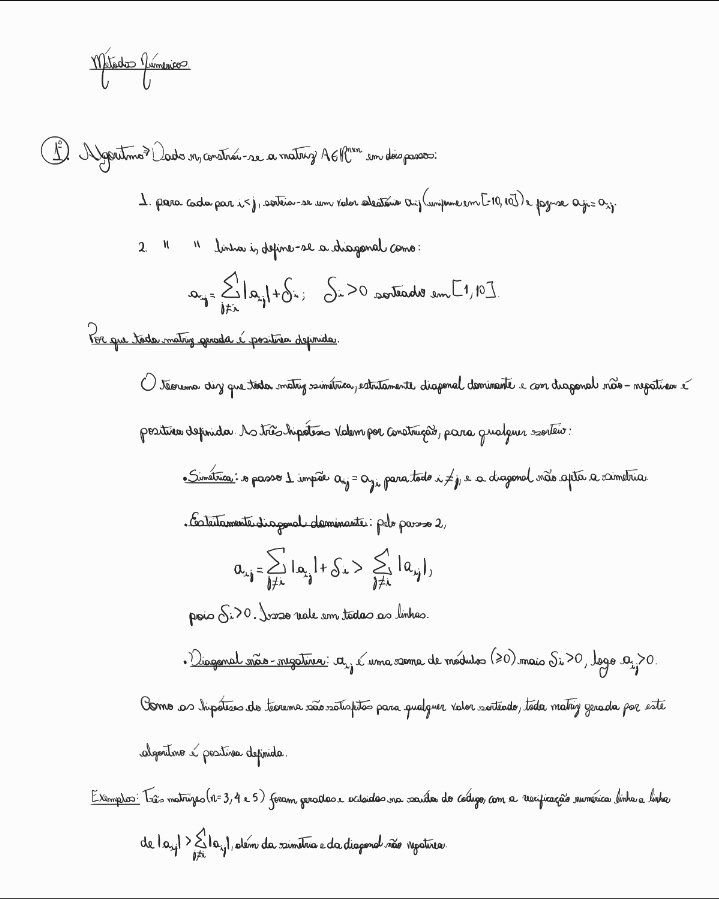

## Questão 2

Executando Experimento a
    n |  Gauss c/ Escala (s) |    Decomp. P^tLU (s) |    Cholesky (s)
----------------------------------------------------------------------
  100 |             0.045423 |             0.041437 |        0.032434
  200 |             0.154869 |             0.189242 |        0.070836
  300 |             0.469312 |             0.393297 |        0.148301
  400 |             3.339956 |             1.722674 |        0.234626
  500 |             2.902181 |             1.767209 |        0.148378

Executando Experimento b
    n |  Gauss c/ Escala (s) |    Decomp. P^tLU (s) |    Cholesky (s)
----------------------------------------------------------------------
  100 |             0.048691 |             0.010255 |        0.009110
  200 |             0.149892 |             0.019809 |        0.011916
  300 |             0.386213 |             0.043347 |        0.018540
  400 |             0.828682 |             0.106310 |        0.025626
  500 |             1.577273 |       

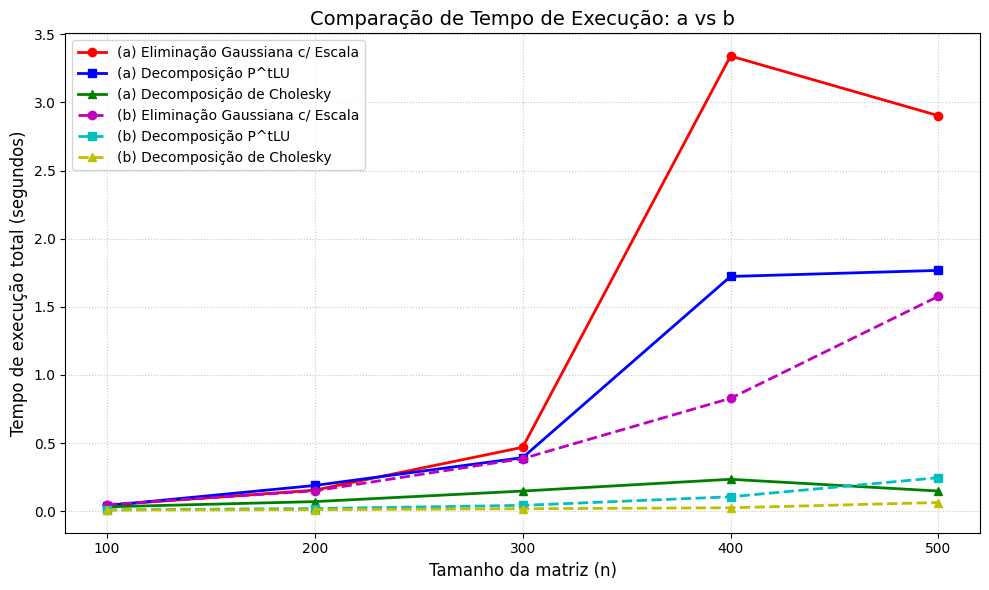


Menor tempo em a (n=500): Cholesky
Menor tempo em b (n=500): Cholesky


In [2]:
import time
import numpy as np
import matplotlib.pyplot as plt

def substituicao_direta(L, b, diag_unitaria=False):

    n = len(b)
    y = np.zeros(n, dtype=float)
    for i in range(n):
        soma = np.dot(L[i, :i], y[:i])
        if diag_unitaria:
            y[i] = b[i] - soma
        else:
            y[i] = (b[i] - soma) / L[i, i]
    return y


def substituicao_reversa(U, y):

    n = len(y)
    x = np.zeros(n, dtype=float)
    for i in range(n - 1, -1, -1):
        soma = np.dot(U[i, i + 1 :], x[i + 1 :])
        x[i] = (y[i] - soma) / U[i, i]
    return x

# ELIMINAÇÃO GAUSSIANA COM PIVOTAGEM PARCIAL COM ESCALA
def eliminacao_gaussiana_escala(A, b):

    n = len(b)
    M = A.astype(float).copy()
    b_mod = b.astype(float).copy()

    # Fatores de escala (máximo valor absoluto de cada linha)
    s = np.max(np.abs(M), axis=1)

    for k in range(n - 1):
        # Escolha da linha pivô com base na razão escalada
        razoes = np.abs(M[k:n, k]) / s[k:n]
        p = k + np.argmax(razoes)

        # Troca de linhas na matriz, no vetor independente e no vetor de escala
        if p != k:
            M[[k, p], :] = M[[p, k], :]
            b_mod[[k, p]] = b_mod[[p, k]]
            s[[k, p]] = s[[p, k]]

        # Eliminação (vetorizada por linha para melhor desempenho)
        fatores = M[k + 1 : n, k] / M[k, k]
        M[k + 1 : n, k:] -= np.outer(fatores, M[k, k:])
        b_mod[k + 1 : n] -= fatores * b_mod[k]

    return substituicao_reversa(M, b_mod)


# DECOMPOSIÇÃO P^t L U
def decomposicao_PtLU(A):

    n = A.shape[0]
    U = A.astype(float).copy()
    L = np.eye(n, dtype=float)
    perm = np.arange(n)

    for k in range(n - 1):
        # Pivotagem parcial padrão
        p = k + np.argmax(np.abs(U[k:n, k]))

        if p != k:
            U[[k, p], :] = U[[p, k], :]
            perm[[k, p]] = perm[[p, k]]
            if k > 0:
                L[[k, p], :k] = L[[p, k], :k]

        fatores = U[k + 1 : n, k] / U[k, k]
        L[k + 1 : n, k] = fatores
        U[k + 1 : n, k:] -= np.outer(fatores, U[k, k:])

    return perm, L, U


def resolver_PtLU(A, b):

    perm, L, U = decomposicao_PtLU(A)
    # Como P^t L U x = b <=> L U x = P b
    b_permutado = b[perm]
    y = substituicao_direta(L, b_permutado, diag_unitaria=True)
    x = substituicao_reversa(U, y)
    return x

# DECOMPOSIÇÃO DE CHOLESKY
def decomposicao_cholesky(A):

    n = A.shape[0]
    G = np.zeros((n, n), dtype=float)

    for i in range(n):
        # Elemento da diagonal
        soma_diag = np.dot(G[i, :i], G[i, :i])
        G[i, i] = np.sqrt(A[i, i] - soma_diag)

        # Elementos abaixo da diagonal na coluna i
        if i + 1 < n:
            soma_col = G[i + 1 : n, :i] @ G[i, :i]
            G[i + 1 : n, i] = (A[i + 1 : n, i] - soma_col) / G[i, i]

    return G


def resolver_cholesky(A, b):

    G = decomposicao_cholesky(A)
    y = substituicao_direta(G, b, diag_unitaria=False)
    x = substituicao_reversa(G.T, y)
    return x


# GERAÇÃO DE DADOS E EXPERIÊNCIA
def gerar_matriz_positiva_definida(n):

    M = np.random.uniform(-5, 5, size=(n, n))
    # M^T * M é semidefinida positiva; somar n*I garante que seja estritamente definida positiva
    return M.T @ M + n * np.eye(n)


def gerar_vetor_b(n):

    b = np.random.uniform(-10, 10, size=n)
    while np.all(b == 0):
        b = np.random.uniform(-10, 10, size=n)
    return b


def executar_experimento():
    valores_n = [100, 200, 300, 400, 500]
    num_matrizes = 10

    # Dicionário para guardar os tempos totais de execução
    tempos = {
        n: {"Gauss_Escala": 0.0, "PtLU": 0.0, "Cholesky": 0.0}
        for n in valores_n
    }

    print(
        f"{'n':>5} | {'Gauss c/ Escala (s)':>20} | {'Decomp. P^tLU (s)':>20} | {'Cholesky (s)':>15}"
    )
    print("-" * 70)

    for n in valores_n:
        # Gera os 10 sistemas previamente para medir apenas o tempo dos métodos
        sistemas = [
            (gerar_matriz_positiva_definida(n), gerar_vetor_b(n))
            for _ in range(num_matrizes)
        ]

        # Eliminação Gaussiana com pivotagem parcial com escala
        inicio = time.perf_counter()
        for A, b in sistemas:
            _ = eliminacao_gaussiana_escala(A, b)
        tempos[n]["Gauss_Escala"] = time.perf_counter() - inicio

        # Decomposição P^t L U
        inicio = time.perf_counter()
        for A, b in sistemas:
            _ = resolver_PtLU(A, b)
        tempos[n]["PtLU"] = time.perf_counter() - inicio

        #  Decomposição de Cholesky
        inicio = time.perf_counter()
        for A, b in sistemas:
            _ = resolver_cholesky(A, b)
        tempos[n]["Cholesky"] = time.perf_counter() - inicio

        print(
            f"{n:>5} | {tempos[n]['Gauss_Escala']:>20.6f} | {tempos[n]['PtLU']:>20.6f} | {tempos[n]['Cholesky']:>15.6f}"
        )

    return tempos

def executar_experimento_b():
    valores_n = [100, 200, 300, 400, 500]
    num_vetores = 10
    tempos_b = {
        n: {"Gauss_Escala": 0.0, "PtLU": 0.0, "Cholesky": 0.0}
        for n in valores_n
    }

    print(
        f"{'n':>5} | {'Gauss c/ Escala (s)':>20} | {'Decomp. P^tLU (s)':>20} | {'Cholesky (s)':>15}"
    )
    print("-" * 70)

    for n in valores_n:
        # Gera 1 única matriz positiva definida A e 10 vetores b != 0
        A = gerar_matriz_positiva_definida(n)
        vetores_b = [gerar_vetor_b(n) for _ in range(num_vetores)]

        # -----------------------------------------------------------------
        # Eliminação Gaussiana com pivotagem parcial com escala (Não reaproveita decomposição: recalcula o escalonamento 10 vezes)
        inicio = time.perf_counter()
        for b in vetores_b:
            _ = eliminacao_gaussiana_escala(A, b)
        tempos_b[n]["Gauss_Escala"] = time.perf_counter() - inicio

        # Decomposição P^t L U (Calcula a fatoração apenas 1 vez e resolve para os 10 vetores b)
        inicio = time.perf_counter()
        perm, L, U = decomposicao_PtLU(A)  # Feito apenas 1 vez para a matriz A
        for b in vetores_b:
            b_permutado = b[perm]
            y = substituicao_direta(L, b_permutado, diag_unitaria=True)
            _ = substituicao_reversa(U, y)
        tempos_b[n]["PtLU"] = time.perf_counter() - inicio

        # 3. Decomposição de Cholesky (Calcula a fatoração apenas 1 vez e resolve para os 10 vetores b)
        inicio = time.perf_counter()
        G = decomposicao_cholesky(A)  # Feito apenas 1 vez para a matriz A
        G_t = G.T
        for b in vetores_b:
            y = substituicao_direta(G, b, diag_unitaria=False)
            _ = substituicao_reversa(G_t, y)
        tempos_b[n]["Cholesky"] = time.perf_counter() - inicio

        print(
            f"{n:>5} | {tempos_b[n]['Gauss_Escala']:>20.6f} | {tempos_b[n]['PtLU']:>20.6f} | {tempos_b[n]['Cholesky']:>15.6f}"
        )

    return tempos_b


def plotar_comparacao(tempos_a, tempos_b):
    valores_n = [100, 200, 300, 400, 500]

    # Extração das listas de tempos para a letra a
    gauss_a = [tempos_a[n]["Gauss_Escala"] for n in valores_n]
    ptlu_a = [tempos_a[n]["PtLU"] for n in valores_n]
    chol_a = [tempos_a[n]["Cholesky"] for n in valores_n]

    # Extração das listas de tempos para a lera b
    gauss_b = [tempos_b[n]["Gauss_Escala"] for n in valores_n]
    ptlu_b = [tempos_b[n]["PtLU"] for n in valores_n]
    chol_b = [tempos_b[n]["Cholesky"] for n in valores_n]

    # Criação de uma única figura contendo as 6 curvas
    plt.figure(figsize=(10, 6))

    # Curvas da a - Linhas contínuas
    plt.plot(
        valores_n,
        gauss_a,
        "r-o",
        label="(a) Eliminação Gaussiana c/ Escala",
        linewidth=2,
    )
    plt.plot(
        valores_n, ptlu_a, "b-s", label="(a) Decomposição P^tLU", linewidth=2
    )
    plt.plot(
        valores_n,
        chol_a,
        "g-^",
        label="(a) Decomposição de Cholesky",
        linewidth=2,
    )

    # Curvas da b - Linhas tracejadas
    plt.plot(
        valores_n,
        gauss_b,
        "m--o",
        label="(b) Eliminação Gaussiana c/ Escala",
        linewidth=2,
    )
    plt.plot(
        valores_n, ptlu_b, "c--s", label="(b) Decomposição P^tLU", linewidth=2
    )
    plt.plot(
        valores_n,
        chol_b,
        "y--^",
        label="(b) Decomposição de Cholesky",
        linewidth=2,
    )

    # Configuração dos eixos, título e legenda
    plt.title(
        "Comparação de Tempo de Execução: a vs b", fontsize=14
    )
    plt.xlabel("Tamanho da matriz (n)", fontsize=12)
    plt.ylabel("Tempo de execução total (segundos)", fontsize=12)
    plt.xticks(valores_n)
    plt.grid(True, linestyle=":", alpha=0.7)
    plt.legend(loc="upper left", fontsize=10)
    plt.tight_layout()

    # Guarda e exibe o gráfico
    plt.savefig("comparacao_6_curvas.png", dpi=300)
    plt.show()


if __name__ == "__main__":
    print("Executando Experimento a")
    tempos_a = executar_experimento()

    print()
    print("Executando Experimento b")
    tempos_b = executar_experimento_b()

    # Plota o gráfico unificado e responde às perguntas no terminal
    plotar_comparacao(tempos_a, tempos_b)

    # Verificação automática do método mais rápido para n = 500
    melhor_a = min(tempos_a[500], key=tempos_a[500].get)
    melhor_b = min(tempos_b[500], key=tempos_b[500].get)
    print(f"\nMenor tempo em a (n=500): {melhor_a}")
    print(f"Menor tempo em b (n=500): {melhor_b}")

## Questão 3

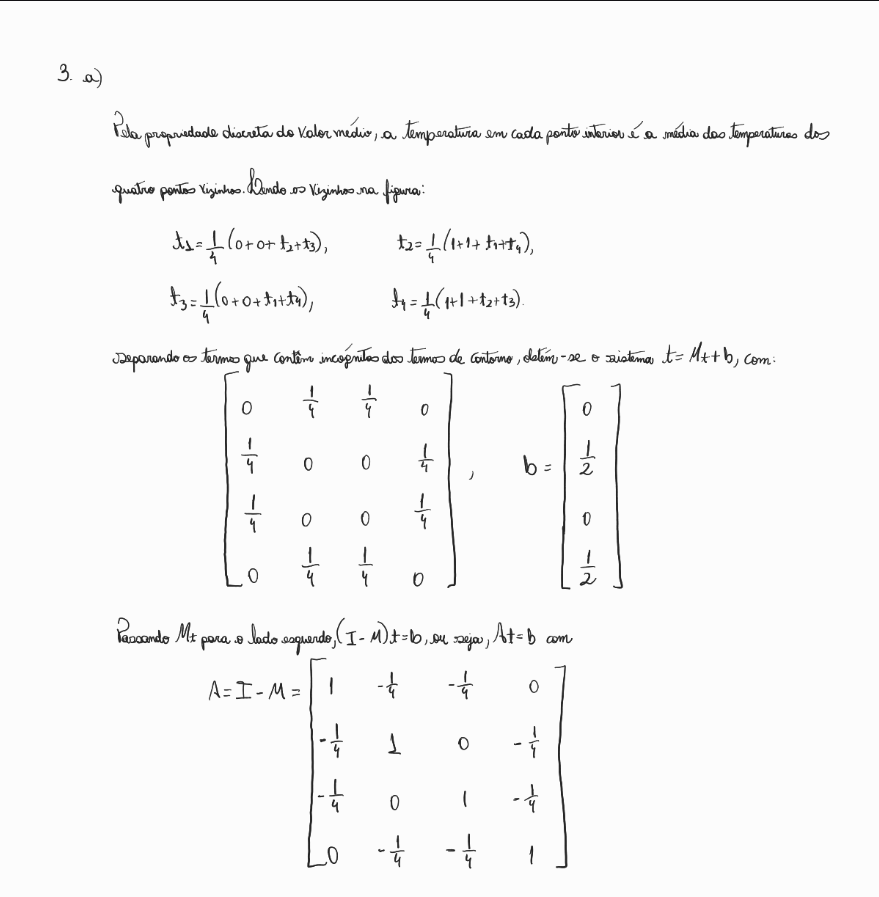

Matriz M:
   [0.0, 0.25, 0.25, 0.0]
   [0.25, 0.0, 0.0, 0.25]
   [0.25, 0.0, 0.0, 0.25]
   [0.0, 0.25, 0.25, 0.0]
Vetor b: [0.0, 0.5, 0.0, 0.5]
Matriz A = I - M:
   [1.0, -0.25, -0.25, 0.0]
   [-0.25, 1.0, 0.0, -0.25]
   [-0.25, 0.0, 1.0, -0.25]
   [0.0, -0.25, -0.25, 1.0]

A e positiva definida? True
Metodo utilizado: Cholesky

Temperaturas nos pontos interiores:
  t1 = 0.250000
  t2 = 0.750000
  t3 = 0.250000
  t4 = 0.750000

Residuo maximo |At - b| = 1.67e-16


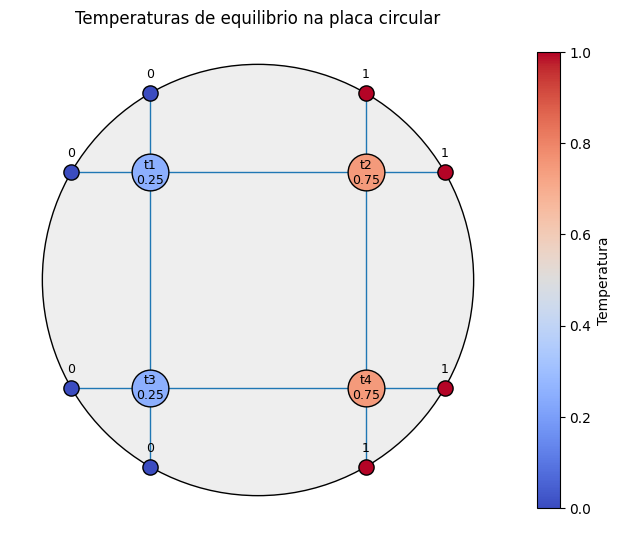


Teste com B = [[1, 2], [2, 1]]: positiva definida? False
Metodo usado: P^t L U, solucao = [1.0, 1.0]


In [3]:
import math
import matplotlib.pyplot as plt
from matplotlib.patches import Circle

def montar_sistema():
    """Monta M, b e A = I - M a partir da propriedade do valor medio."""
    M = [
        [0.0, 0.25, 0.25, 0.0],
        [0.25, 0.0, 0.0, 0.25],
        [0.25, 0.0, 0.0, 0.25],
        [0.0, 0.25, 0.25, 0.0],
    ]
    b = [0.0, 0.5, 0.0, 0.5]
    n = len(b)
    A = [[(1.0 if i == j else 0.0) - M[i][j] for j in range(n)] for i in range(n)]
    return M, b, A

def substituicao_direta(L, b, diag_unitaria=False):
    n = len(b)
    y = [0.0] * n
    for i in range(n):
        soma = sum(L[i][k] * y[k] for k in range(i))
        if diag_unitaria:
            y[i] = b[i] - soma
        else:
            y[i] = (b[i] - soma) / L[i][i]
    return y

def substituicao_reversa(U, y):
    n = len(y)
    x = [0.0] * n
    for i in range(n - 1, -1, -1):
        soma = sum(U[i][k] * x[k] for k in range(i + 1, n))
        x[i] = (y[i] - soma) / U[i][i]
    return x

def cholesky_com_teste(A, tol=1e-12):
    """Decomposicao de Cholesky A = G G^T que tambem testa se A e positiva definida.

    Retorna (G, True) se A for positiva definida e (None, False) caso contrario.
    Se algum valor dentro da raiz quadrada for <= 0, A nao e positiva definida.
    """
    n = len(A)

    # Cholesky so se aplica a matrizes simetricas
    for i in range(n):
        for j in range(i):
            if abs(A[i][j] - A[j][i]) > tol:
                return None, False

    G = [[0.0] * n for _ in range(n)]
    for i in range(n):
        for j in range(i + 1):
            soma = sum(G[i][k] * G[j][k] for k in range(j))
            if i == j:
                valor = A[i][i] - soma
                if valor <= tol:
                    return None, False
                G[i][i] = math.sqrt(valor)
            else:
                G[i][j] = (A[i][j] - soma) / G[j][j]
    return G, True

def resolver_cholesky(G, b):
    n = len(G)
    Gt = [[G[j][i] for j in range(n)] for i in range(n)]
    y = substituicao_direta(G, b)
    return substituicao_reversa(Gt, y)

def decomposicao_PtLU(A):
    """Decomposicao P^t L U com pivoteamento parcial: A = P^t L U."""
    n = len(A)
    U = [linha[:] for linha in A]
    L = [[1.0 if i == j else 0.0 for j in range(n)] for i in range(n)]
    perm = list(range(n))

    for k in range(n - 1):
        p = max(range(k, n), key=lambda i: abs(U[i][k]))
        if p != k:
            U[k], U[p] = U[p], U[k]
            perm[k], perm[p] = perm[p], perm[k]
            for j in range(k):
                L[k][j], L[p][j] = L[p][j], L[k][j]
        for i in range(k + 1, n):
            fator = U[i][k] / U[k][k]
            L[i][k] = fator
            for j in range(k, n):
                U[i][j] -= fator * U[k][j]

    return perm, L, U

def resolver_PtLU(A, b):
    perm, L, U = decomposicao_PtLU(A)
    b_perm = [b[perm[i]] for i in range(len(b))]
    y = substituicao_direta(L, b_perm, diag_unitaria=True)
    return substituicao_reversa(U, y)

def resolver_sistema(A, b):
    """Usa Cholesky se A for positiva definida; caso contrario, P^t L U."""
    G, eh_pd = cholesky_com_teste(A)
    if eh_pd:
        return resolver_cholesky(G, b), "Cholesky"
    return resolver_PtLU(A, b), "P^t L U"

def residuo_maximo(A, x, b):
    n = len(b)
    return max(abs(sum(A[i][j] * x[j] for j in range(n)) - b[i]) for i in range(n))

def plotar_placa(t):
    """Reproduz a figura da placa: pontos da malha coloridos pela temperatura."""
    c = 0.5                     # coordenada dos pontos interiores: x, y em {-c, c}
    s = math.sqrt(1 - c * c)    # coordenada dos pontos de contorno sobre o circulo
    mapa = plt.get_cmap("coolwarm")

    fig, ax = plt.subplots(figsize=(6.5, 6))
    ax.add_patch(Circle((0, 0), 1.0, facecolor="#eeeeee", edgecolor="black", zorder=0))

    # Linhas da malha
    for v in (-c, c):
        ax.plot([v, v], [-s, s], color="tab:blue", linewidth=1, zorder=1)
        ax.plot([-s, s], [v, v], color="tab:blue", linewidth=1, zorder=1)

    # Pontos de contorno: 0 na metade esquerda, 1 na metade direita
    contorno = [
        (-c, s, 0), (c, s, 1),      # em cima
        (-c, -s, 0), (c, -s, 1),    # embaixo
        (-s, c, 0), (s, c, 1),      # esquerda e direita (linha de cima)
        (-s, -c, 0), (s, -c, 1),    # esquerda e direita (linha de baixo)
    ]
    for x, y, temp in contorno:
        ax.scatter(x, y, s=120, color=mapa(float(temp)), edgecolors="black", zorder=3)
        ax.annotate(f"{temp}", (x, y), textcoords="offset points", xytext=(0, 11),
                    ha="center", fontsize=9)

    # Pontos interiores t1, t2, t3, t4
    interiores = [(-c, c), (c, c), (-c, -c), (c, -c)]
    for i, ((x, y), temp) in enumerate(zip(interiores, t), start=1):
        ax.scatter(x, y, s=700, color=mapa(temp), edgecolors="black", zorder=4)
        ax.annotate(f"t{i}\n{temp:.2f}", (x, y), ha="center", va="center",
                    fontsize=9, zorder=5)

    barra = plt.cm.ScalarMappable(cmap=mapa, norm=plt.Normalize(0, 1))
    fig.colorbar(barra, ax=ax, label="Temperatura", shrink=0.8)

    ax.set_aspect("equal")
    ax.set_xlim(-1.15, 1.15)
    ax.set_ylim(-1.15, 1.15)
    ax.set_title("Temperaturas de equilibrio na placa circular")
    ax.axis("off")
    plt.tight_layout()
    plt.savefig("questao3c_placa.png", dpi=200)
    plt.show()

if __name__ == "__main__":
    M, b, A = montar_sistema()

    print("Matriz M:")
    for linha in M:
        print("  ", linha)
    print("Vetor b:", b)
    print("Matriz A = I - M:")
    for linha in A:
        print("  ", linha)

    G, eh_pd = cholesky_com_teste(A)
    print(f"\nA e positiva definida? {eh_pd}")

    t, metodo = resolver_sistema(A, b)
    print(f"Metodo utilizado: {metodo}")
    print("\nTemperaturas nos pontos interiores:")
    for i, valor in enumerate(t, start=1):
        print(f"  t{i} = {valor:.6f}")
    print(f"\nResiduo maximo |At - b| = {residuo_maximo(A, t, b):.2e}")

    # Item (c): figura da placa
    plotar_placa(t)

    # Teste do desvio: matriz simetrica que NAO e positiva definida
    B = [[1.0, 2.0], [2.0, 1.0]]
    _, pd_B = cholesky_com_teste(B)
    print(f"\nTeste com B = [[1, 2], [2, 1]]: positiva definida? {pd_B}")
    xB, metodo_B = resolver_sistema(B, [3.0, 3.0])
    print(f"Metodo usado: {metodo_B}, solucao = {xB}")

**Resultado:** a matriz $A = I - M$ é positiva definida (o Cholesky concluiu sem erro), então o sistema foi resolvido por Cholesky. As temperaturas obtidas são $t_1 = t_3 = 0{,}25$ e $t_2 = t_4 = 0{,}75$: a metade esquerda da placa é mais fria e a direita mais quente, coerente com as condições de contorno.

## Questão 4

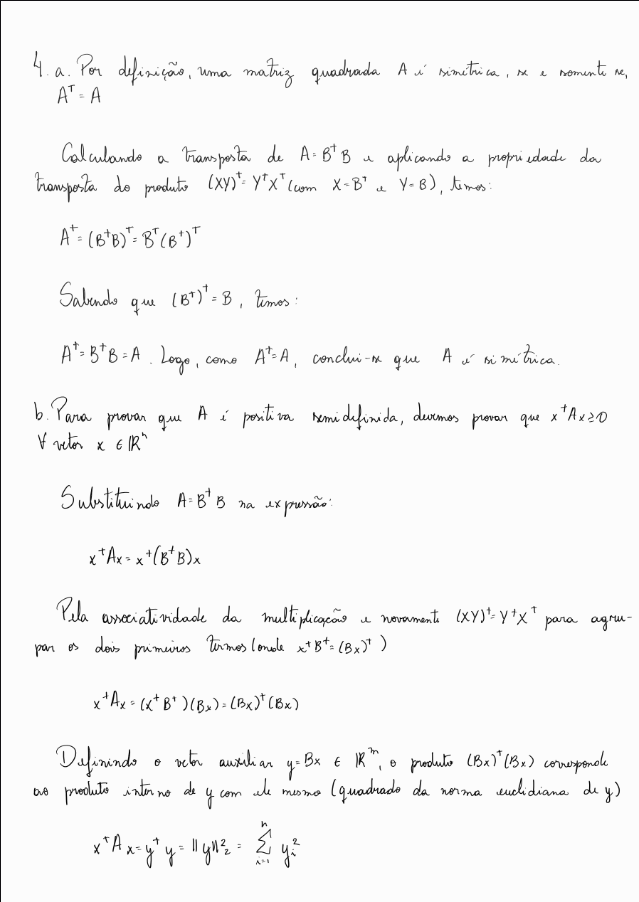

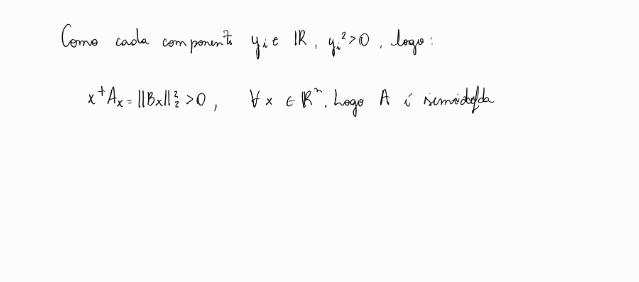